Part a

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc
from sklearn.naive_bayes import GaussianNB
import seaborn as sns

# Loading the dataset
digits = load_digits()
X = digits.data
y = digits.target

# Split into training and testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Estimating the class priors for each digit (0-9)
class_priors = np.bincount(y_train) / len(y_train)
print("Class Priors:", class_priors)

C:\Program Files\Anaconda\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.25.0
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Class Priors: [0.09944312 0.10501193 0.10342084 0.1026253  0.09626094 0.09228321
 0.10182975 0.09864757 0.10421639 0.09626094]


Part b

In [2]:
# Estimating the class-conditional mean and covariance matrix for each digit class
num_classes = 10
num_features = X_train.shape[1]
class_means = np.zeros((num_classes, num_features))
class_covariances = np.zeros((num_classes, num_features, num_features))
for i in range(num_classes):
    X_class = X_train[y_train == i]
    class_means[i] = np.mean(X_class, axis=0)
    class_covariances[i] = np.cov(X_class, rowvar=False) + 1e-6 * np.identity(num_features)  # Adding small value to avoid singular matrix

Part c

In [3]:
# Implementing Bayesian classifier
def multivariate_gaussian(x, mean, cov):
    size = len(mean)
    det = np.linalg.det(cov)
    norm_const = 1.0 / (np.power((2 * np.pi), float(size) / 2) * np.sqrt(det))
    x_mu = x - mean
    inv_cov = np.linalg.inv(cov)
    result = np.exp(-0.5 * (np.dot(np.dot(x_mu, inv_cov), x_mu.T)))
    return norm_const * result

def bayesian_classifier(X):
    predicted_labels = []
    for x in X:
        posteriors = []
        for i in range(num_classes):
            likelihood = multivariate_gaussian(x, class_means[i], class_covariances[i])
            posterior = class_priors[i] * likelihood
            posteriors.append(posterior)
        predicted_labels.append(np.argmax(posteriors))
    return np.array(predicted_labels)

# Classifying the test set using our Bayesian classifier
y_pred_manual = bayesian_classifier(X_test)

Part d

Manual Bayesian Classifier Accuracy: 0.95
Sklearn GaussianNB Accuracy: 0.85


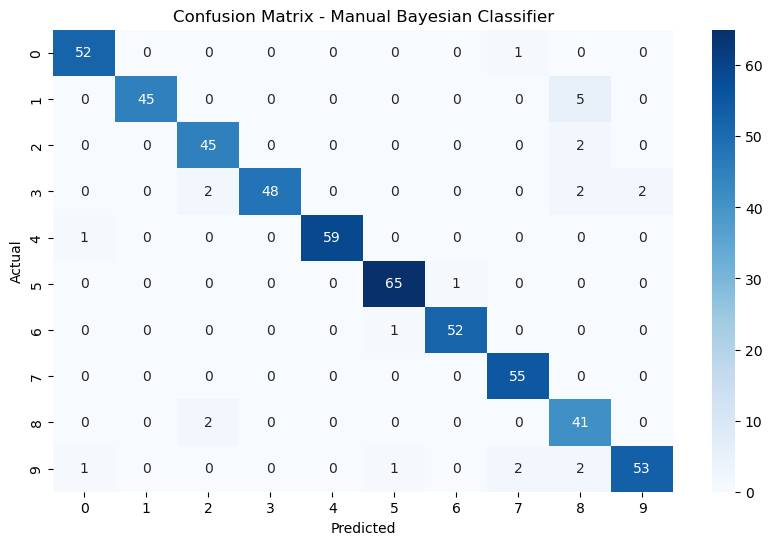

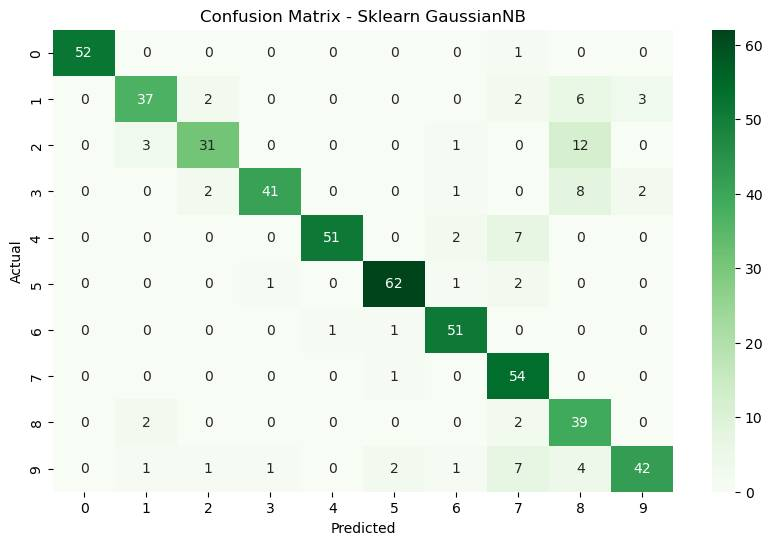

In [4]:
# Comparing with GaussianNB from scikit-learn
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_sklearn = gnb.predict(X_test)

# Evaluating performance
accuracy_manual = accuracy_score(y_test, y_pred_manual)
accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)
print(f"Manual Bayesian Classifier Accuracy: {accuracy_manual:.2f}")
print(f"Sklearn GaussianNB Accuracy: {accuracy_sklearn:.2f}")

# Confusion matrix for manual Bayesian classifier
conf_matrix_manual = confusion_matrix(y_test, y_pred_manual)
plt.figure(figsize=(10, 6))
sns.heatmap(conf_matrix_manual, annot=True, cmap="Blues", fmt="g")
plt.title("Confusion Matrix - Manual Bayesian Classifier")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Confusion matrix for scikit-learn GaussianNB
conf_matrix_sklearn = confusion_matrix(y_test, y_pred_sklearn)
plt.figure(figsize=(10, 6))
sns.heatmap(conf_matrix_sklearn, annot=True, cmap="Greens", fmt="g")
plt.title("Confusion Matrix - Sklearn GaussianNB")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Part e

In [5]:
# Computing the Bayes error for classifier
bayes_error_manual = 1 - accuracy_manual
print(f"Bayes Error for Manual Bayesian Classifier: {bayes_error_manual:.2f}")

Bayes Error for Manual Bayesian Classifier: 0.05


Part f

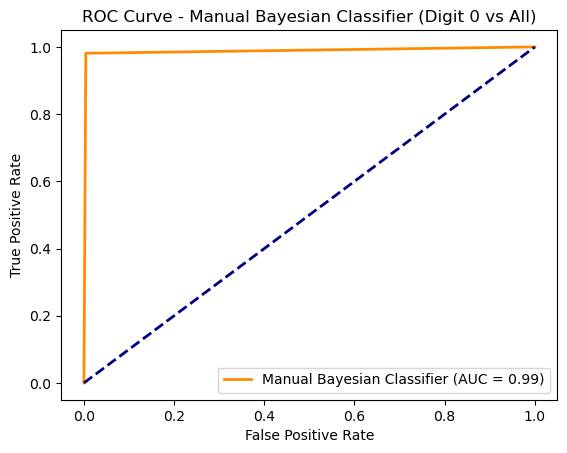

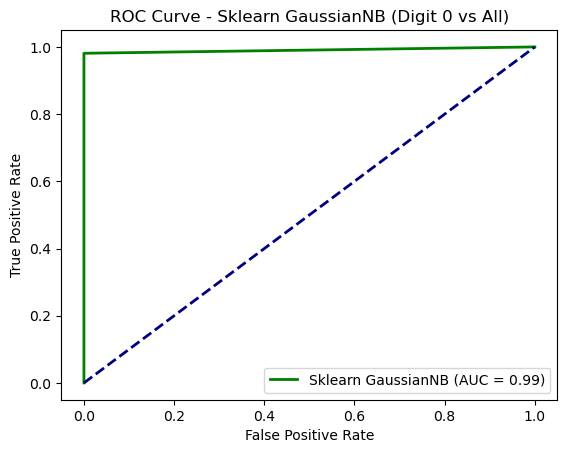

In [6]:
# Ploting the ROC curve to evaluate the classifier's performance (One-vs-All for Digit 0)
fpr_manual, tpr_manual, _ = roc_curve(y_test == 0, y_pred_manual == 0)
roc_auc_manual = auc(fpr_manual, tpr_manual)

plt.figure()
plt.plot(fpr_manual, tpr_manual, color='darkorange', lw=2, label=f'Manual Bayesian Classifier (AUC = {roc_auc_manual:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Manual Bayesian Classifier (Digit 0 vs All)')
plt.legend(loc="lower right")
plt.show()

# ROC Curve for Scikit-Learn GaussianNB (Binary Example for Digit 0)
fpr_sklearn, tpr_sklearn, _ = roc_curve(y_test == 0, y_pred_sklearn == 0)
roc_auc_sklearn = auc(fpr_sklearn, tpr_sklearn)

plt.figure()
plt.plot(fpr_sklearn, tpr_sklearn, color='green', lw=2, label=f'Sklearn GaussianNB (AUC = {roc_auc_sklearn:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Sklearn GaussianNB (Digit 0 vs All)')
plt.legend(loc="lower right")
plt.show()